---
numbering: false
---

# Determine NDI thresholds using Otsu's Method

In the Week 5 material, we used [manual inspection of a histogram to determine NDI thresholds](../week/05/02-band-maths.ipynb#putting-normalised-difference-indices-into-practice) from a slightly messy (i.e. not clearly bimodal) distribution of NDI values.

In some scenarios, you might be more confident in saying that your scene is likely to contain a clear bimodal distribution: e.g., if  your study area of interest is clipped tightly to one object such as lake or glacier, then the surface and non-surface values will be approximately equal.

In this scenario, we can revert to a common computer vision/image processing method known as [Otsu's method](https://en.wikipedia.org/wiki/Otsu%27s_method) to perform an automatic image threshold. This might be useful if you have a full stack of imagery, allowing you to quickly determine a reasonable threshold for each image in a stack.

In [5]:
import xarray as xr
import rioxarray as rxr
import numpy as np

import matplotlib.pyplot as plt

## Otsu's Method function

A couple of Python libraries offer an Otsu function, including [the `scikit-image` library](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_thresholding.html) and [the OpenCV python API](https://docs.opencv.org/3.4.20/d7/d4d/tutorial_py_thresholding.html). However, the actual function is simple to implement (and one approach is even [summarised in the Wikipedia page!](https://en.wikipedia.org/wiki/Otsu%27s_method#Python_implementation)), so we can just as easily make a function ourselves rather than install (and learn the syntax for) a whole new package just for one task.

In [ ]:
def threshold_otsu(data, bin= 256):
    """
    Calculate Otsu's threshold for an xarray DataArray.

    Parameters
    ----------
    data : xarray.DataArray | np.ndarray
        The input data array for which to compute the Otsu threshold.
    bin : int, optional
        The number of bins to use for the histogram. Default is 256.
    """

    # if the input is an xarray DataArray, convert it to a numpy array
    if isinstance(data, xr.DataArray):
        values = data.values
    elif isinstance(data, np.ndarray):
        values = data
    else:
        raise TypeError("Input must be an xarray DataArray or a numpy ndarray.")

    # clean array
    values = values[np.isfinite(values)]  # Remove NaN values

    # If the array is empty after removing NaNs, return None
    if values.size == 0:
        return None

    # Construct histogram and get centrepoints of bins
    hist, bin_edges = np.histogram(values, bins=bin, range=(values.min(), values.max()))
    centres = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Otsu's method

    weight1 = np.cumsum(hist)
    weight2 = values.size - weight1

    sum1 = np.cumsum(hist * centres)
    total = sum1[-1]

    mean1 = sum1 / np.maximum(weight1, 1)
    mean2 = (total - sum1) / np.maximum(weight2, 1)

    variance = weight1 * weight2 * (mean1 - mean2) ** 2
    variance[weight2 == 0] = 0

    return float(centres[np.argmax(variance)])

Feel free to copy this function into your own work.

## Showing it works

Let's construct a simple sample bimodal array to show how the Otsu function determines a threshold.

In [19]:
# Create a random number generator with a fixed seed for reproducibility
rng = np.random.default_rng(42)

# By tradition, the fixed seed is 42, but you can choose any integer value.
# This ensures that the random numbers generated are the same every time 
# the code is run. 42 is a reference to "The Hitchhiker's Guide to the Galaxy" 
# where 42 is the answer to the ultimate question of life, the universe, and 
# everything.

# Generate two populations
lower = rng.normal(loc=-0.1, scale=0.2, size=(100, 100))
upper = rng.normal(loc=0.6, scale=0.2, size=(100, 100))

# Combine into a bimodal 2D array
data = np.concatenate([lower, upper], axis=1)

# Create an xarray DataArray
da = xr.DataArray(
    data,
    dims=("y", "x"),
    name="Normalised Difference Index",
)

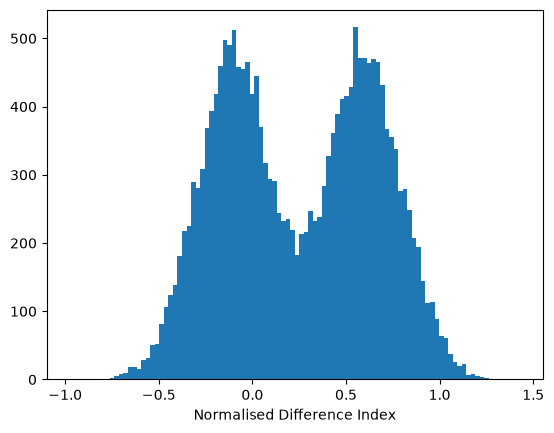

In [21]:
da.plot.hist(bins=100)
plt.show()

Otsu's threshold will return a recommended threshold, hopefully in the 'saddle' of the bimodal distribution:

In [25]:
threshold = threshold_otsu(da)
print("Otsu's threshold:", threshold)

Otsu's threshold: 0.24032247338377066


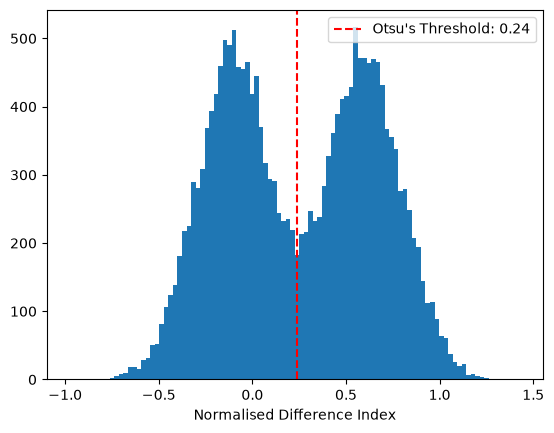

In [28]:
fig, ax = plt.subplots()

da.plot.hist(bins=100, ax=ax)

ax.axvline(threshold, color='r', linestyle='--', label=f"Otsu's Threshold: {threshold:.2f}")

ax.legend()
ax.set_xlabel("Normalised Difference Index")
plt.show()


## Real Example

Let's use the same data as in week 5, focussing on the example of the lake.

In [46]:
# load the Landsat 8 scene
scene = rxr.open_rasterio("LC08_L2SP_042034_20260609_20260613_02_T1_SR.tif")
scene['band'] = list(scene.attrs['long_name'])

# clip to the bounding box of the area of interest
bbox = [339860, 4159488, 349640, 4167004]
scene = scene.rio.clip_box(*bbox)

# replace negative values with 0
scene = scene.where(scene >= 0, 0)  

# generate rgb and ndwi images
rgb = scene.sel(band=['red', 'green', 'blue'])
ndwi = scene.sel(band='green') - scene.sel(band='nir') / (scene.sel(band='green') + scene.sel(band='nir'))

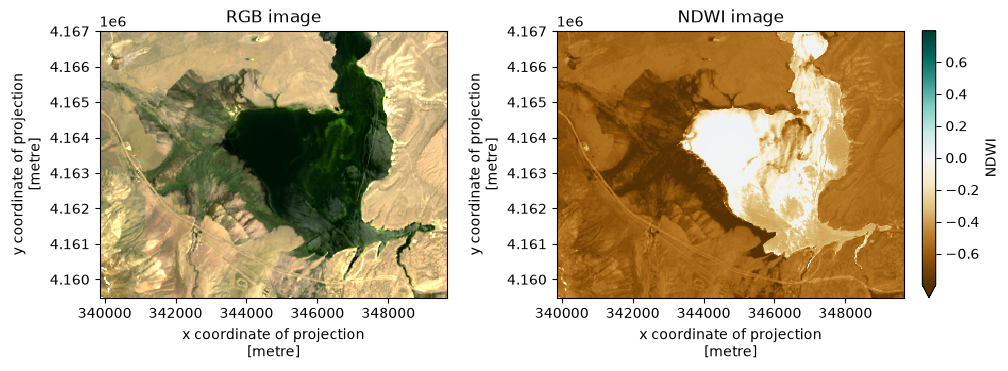

In [70]:
fig, axes = plt.subplots(ncols=2, layout='constrained', figsize=(10, 3.6))

ax = axes[0]
rgb.plot.imshow(ax=ax, robust=True)
ax.set_aspect('equal')
ax.set_title("RGB image")

ax = axes[1]
ndwi.plot.imshow(ax=ax, cmap='BrBG', robust=True, cbar_kwargs={'label': 'NDWI'})
ax.set_aspect('equal')
ax.set_title("NDWI image")

plt.show()

We can determine the threshold, and plot it to assess:

In [59]:
threshold = threshold_otsu(ndwi)
print("Otsu's threshold for NDWI:", threshold)

Otsu's threshold for NDWI: -0.3710017800331116


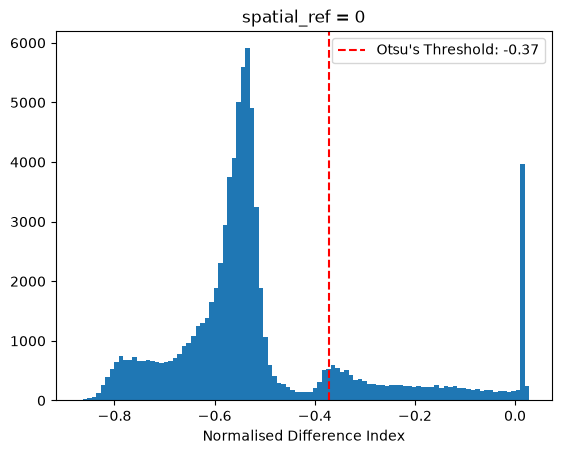

In [61]:
fig, ax = plt.subplots()

ndwi.plot.hist(bins=100, ax=ax)

ax.axvline(threshold, color='r', linestyle='--', label=f"Otsu's Threshold: {threshold:.2f}")

ax.legend()
ax.set_xlabel("Normalised Difference Index")
plt.show()


This isn't a perfect bimodal distribution, but we can test and see how it is:

In [65]:
# construct boolean water mask
water_mask = ndwi > threshold

# replace 0 values with NaN for better visualization
water_mask = water_mask.where(water_mask, np.nan)


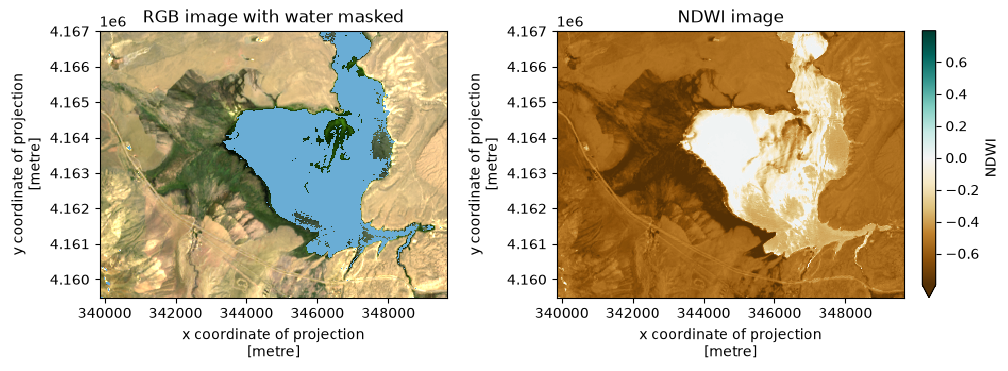

In [71]:
fig, axes = plt.subplots(ncols=2, layout='constrained', figsize=(10, 3.6))

ax = axes[0]
rgb.plot.imshow(ax=ax, robust=True)

water_mask.plot.imshow(ax=ax, cmap='Blues', add_colorbar=False)

ax.set_aspect('equal')
ax.set_title("RGB image with water masked")

ax = axes[1]
ndwi.plot.imshow(ax=ax, cmap='BrBG', robust=True, cbar_kwargs={'label': 'NDWI'})
ax.set_aspect('equal')
ax.set_title("NDWI image")

plt.show()

This is a pretty good attempt! Remember, this won't always work in a 'real' scenario, and you should manually assess each attempt rather than trusting it blindly.